Loading I-JEPA ViT-H/14...


config.json:   0%|          | 0.00/497 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

Model loaded!

  Loaded: beagle (norm=17.6)
  Loaded: cat (norm=16.2)
  Loaded: person (norm=17.2)
  Loaded: french_bulldog (norm=16.5)

Cosine Similarity Matrix:
           beagle: 1.000 0.319 0.300 0.370
              cat: 0.319 1.000 0.449 0.428
           person: 0.300 0.449 1.000 0.467
   french_bulldog: 0.370 0.428 0.467 1.000

RUNNING STANDARD MODEL (normalized, no Bayesian)
Final activations: {'beagle': '0.0956', 'cat': '0.0481', 'person': '0.0332', 'french_bulldog': '0.0271'}
Survivors: 4/4

RUNNING BAYESIAN MODEL (normalized + confidence)
Final activations: {'beagle': '0.0906', 'cat': '0.0486', 'person': '0.0343', 'french_bulldog': '0.0277'}
Final confidence:  {'beagle': '0.0100', 'cat': '0.0100', 'person': '0.0100', 'french_bulldog': '0.0100'}
Survivors: 4/4


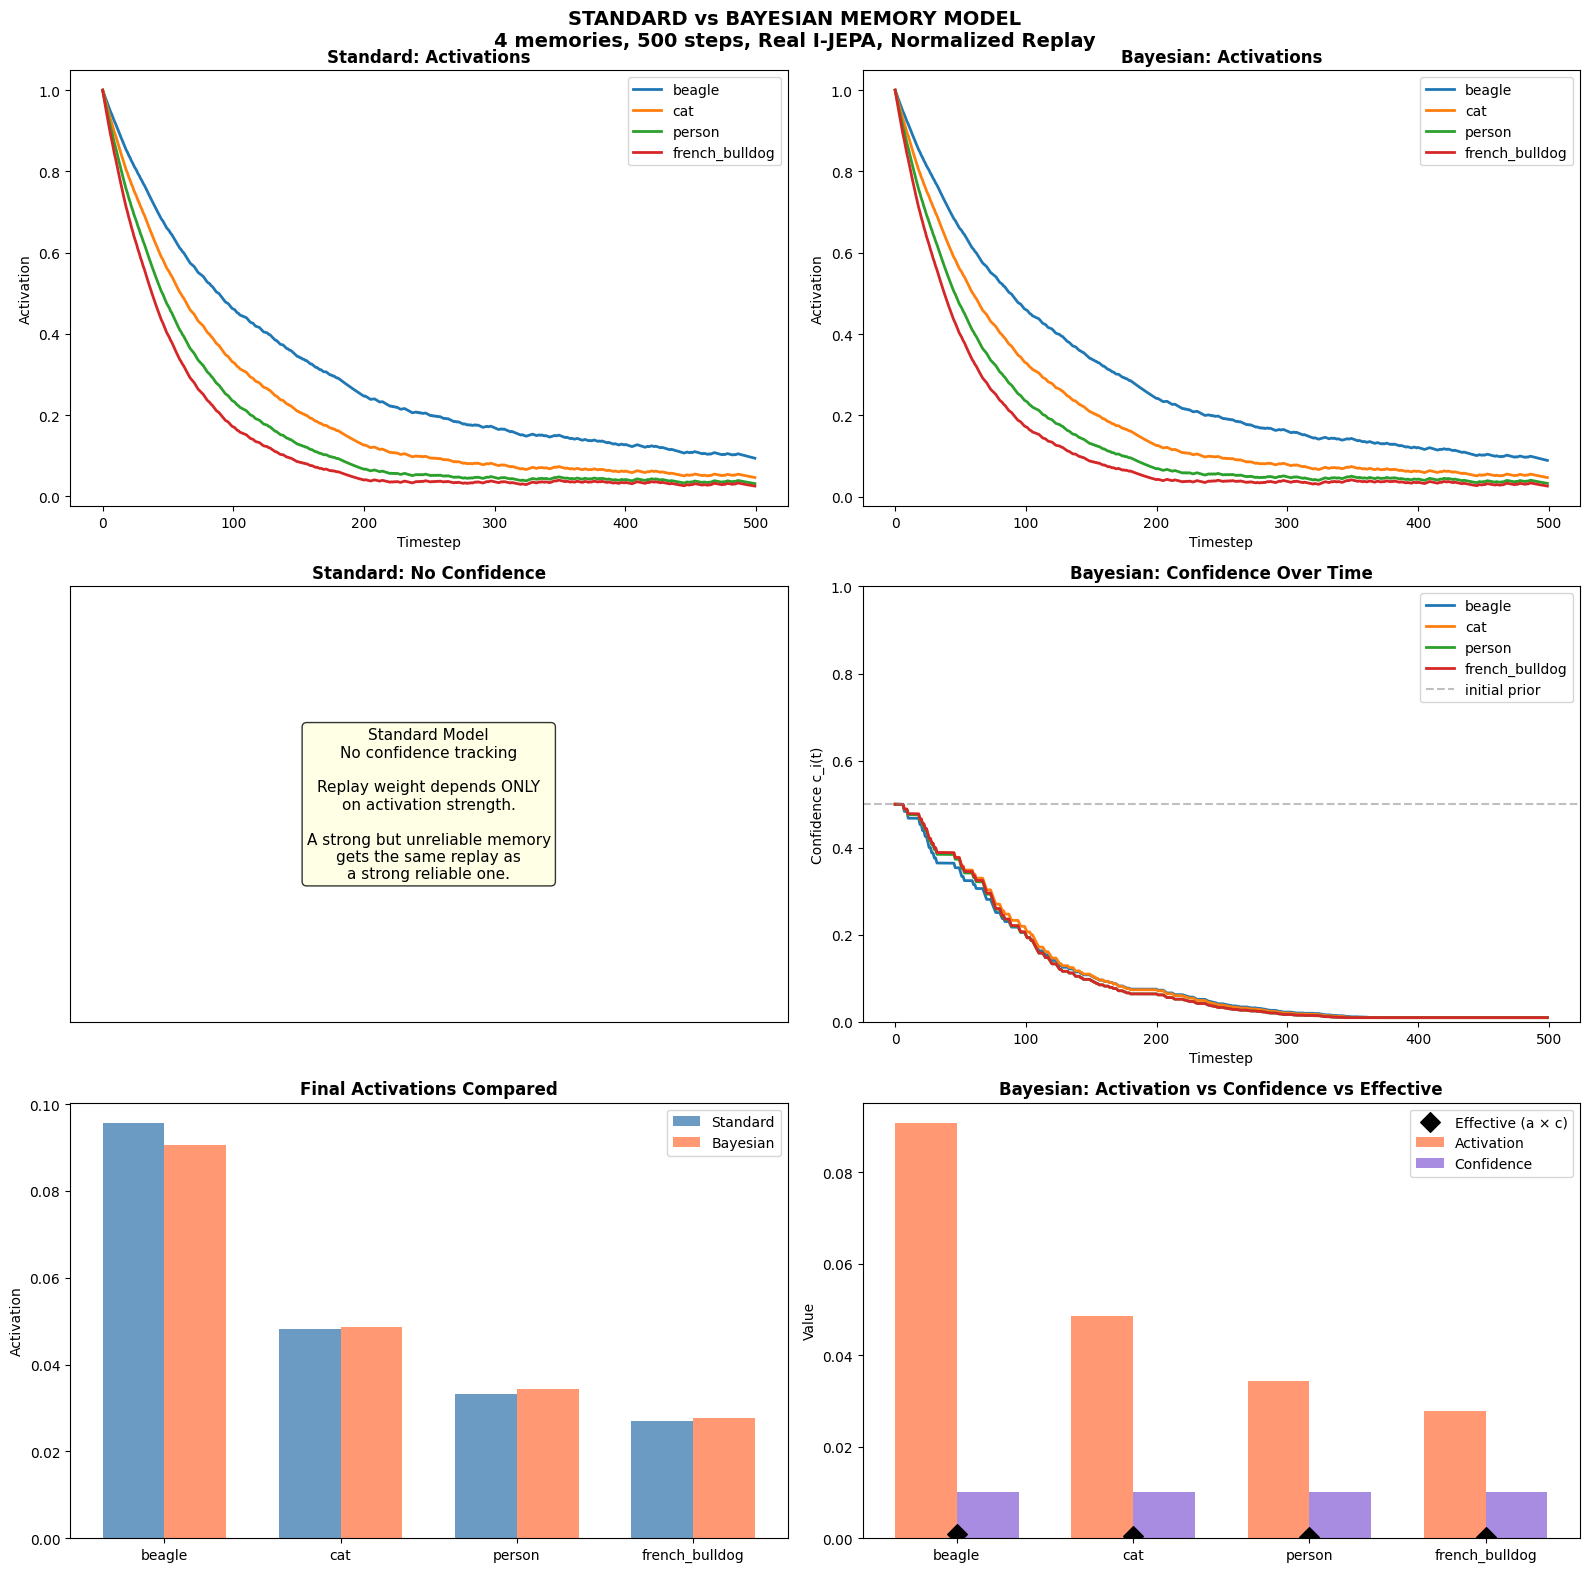


ANALYSIS: WHAT BAYESIAN CONFIDENCE ADDS

1. ACTIVATION COMPARISON:
  Memory            Standard   Bayesian Difference
  beagle              0.0956     0.0906    -0.0049
  cat                 0.0481     0.0486    +0.0006
  person              0.0332     0.0343    +0.0011
  french_bulldog      0.0271     0.0277    +0.0006

2. BAYESIAN CONFIDENCE (what the standard model CAN'T tell you):
  beagle         : confidence = 0.0100, effective strength = 0.0009
  cat            : confidence = 0.0100, effective strength = 0.0005
  person         : confidence = 0.0100, effective strength = 0.0003
  french_bulldog : confidence = 0.0100, effective strength = 0.0003

3. KEY INSIGHT:
  Standard model: memory strength = activation only
  Bayesian model: memory strength = activation × confidence
  A memory can be STRONG (high activation) but UNRELIABLE (low confidence)
  Or WEAK (low activation) but CONFIDENT (high confidence)
  This distinction matters for real memory systems!

THE MATH

STANDARD (pap

In [1]:
"""
BAYESIAN MEMORY CONFIDENCE + MARKOV STATE TRANSITIONS
======================================================
Extension of the paper's master equation with:
1. Bayesian confidence tracking per memory
2. Confidence-weighted replay (uncertain memories get less replay)
3. Confidence updates via Bayesian inference at each replay event

Base: Normalized replay (our fix), N=4, T=500, paper's params
New: Each memory has activation (strength) + confidence (reliability)
"""

import torch
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO
from transformers import AutoModel, AutoProcessor

# ============================================================
# 1. LOAD I-JEPA
# ============================================================
print("Loading I-JEPA ViT-H/14...")
model = AutoModel.from_pretrained("facebook/ijepa_vith14_1k")
processor = AutoProcessor.from_pretrained("facebook/ijepa_vith14_1k")
model.eval()
print("Model loaded!\n")

# ============================================================
# 2. LOAD IMAGES (same 4 as Run 1)
# ============================================================
urls = [
    "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400",  # beagle
    "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400",  # cat
    "https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400",  # person
    "https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400",  # french bulldog
]
labels = ["beagle", "cat", "person", "french_bulldog"]

embeddings = []
for url, label in zip(urls, labels):
    response = requests.get(url, timeout=10)
    img = Image.open(BytesIO(response.content)).convert('RGB')
    inputs = processor(images=img, return_tensors="pt")
    with torch.no_grad():
        outputs = model(**inputs)
    emb = outputs.last_hidden_state.mean(dim=1).squeeze()
    embeddings.append(emb)
    print(f"  Loaded: {label} (norm={emb.norm():.1f})")

X = torch.stack(embeddings)
X_norm = X / X.norm(dim=1, keepdim=True)
N = len(labels)

# Cosine similarity
cos_sim = (X_norm @ X_norm.T).numpy()
print(f"\nCosine Similarity Matrix:")
for i in range(N):
    row = " ".join([f"{cos_sim[i][j]:.3f}" for j in range(N)])
    print(f"  {labels[i]:>15}: {row}")

# ============================================================
# 3. STANDARD MODEL (Normalized, no Bayesian) — baseline
# ============================================================
def run_standard(X_norm, T=500, dt=0.01, beta=3.0, eta=0.8, p=0.3,
                 gamma=0.2, delta=0.1, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    N = X_norm.shape[0]
    A = torch.linspace(0.5, 1.5, N)

    S = X_norm @ X_norm.T
    W = S.clone(); W.fill_diagonal_(0)
    D = torch.diag(W.sum(dim=1))
    L = D - W

    activations = torch.ones(N)
    history = []

    for t in range(T):
        history.append(activations.clone().numpy())
        a = activations
        decay = -A * a
        diffusion = -gamma * (L @ a)
        inhibition = -delta * a.sum() * torch.ones(N)
        stim = (torch.rand(1).item() < p)
        if stim:
            scores = X_norm @ X_norm.T @ a
            rw = torch.softmax(beta * scores, dim=0)
            replay = eta * rw
        else:
            replay = torch.zeros(N)
        da = decay + diffusion + inhibition + replay
        activations = torch.clamp(a + dt * da, min=0)

    return np.array(history), activations.numpy()

# ============================================================
# 4. BAYESIAN MEMORY MODEL
# ============================================================
def run_bayesian(X_norm, T=500, dt=0.01, beta=3.0, eta=0.8, p=0.3,
                 gamma=0.2, delta=0.1, seed=42,
                 prior_confidence=0.5,       # initial confidence
                 confidence_boost=0.05,      # how much replay boosts confidence
                 confidence_decay_rate=0.01, # natural confidence decay
                 confidence_weight=0.5):     # how much confidence affects replay
    """
    Each memory i has:
      - a_i(t): activation (strength) — same as paper
      - c_i(t): confidence (reliability) — NEW, range [0, 1]

    Bayesian update rule:
      When memory i is replayed:
        likelihood = similarity between memory i and replay signal
        prior = current confidence c_i
        posterior ∝ likelihood × prior  (Bayes rule)

    Confidence-weighted replay:
      F_bayesian(a) = softmax(β × XᵀX × (a ⊙ c))
      Memories with low confidence get less replay weight
      even if their activation is high.

    Confidence decay:
      dc/dt = -λ_c × c  (unrehearsed memories lose confidence)
      Replay boosts confidence (rehearsal = reinforcement)
    """
    torch.manual_seed(seed)
    np.random.seed(seed)
    N = X_norm.shape[0]
    A = torch.linspace(0.5, 1.5, N)

    S = X_norm @ X_norm.T
    W = S.clone(); W.fill_diagonal_(0)
    D = torch.diag(W.sum(dim=1))
    L = D - W

    # Activation + Confidence
    activations = torch.ones(N)
    confidence = torch.full((N,), prior_confidence)

    act_history = []
    conf_history = []
    replay_history = []

    for t in range(T):
        act_history.append(activations.clone().numpy())
        conf_history.append(confidence.clone().numpy())

        a = activations
        c = confidence

        # === ACTIVATION DYNAMICS (same as paper + normalized) ===
        decay = -A * a
        diffusion = -gamma * (L @ a)
        inhibition = -delta * a.sum() * torch.ones(N)

        stim = (torch.rand(1).item() < p)
        if stim:
            # KEY CHANGE: confidence-weighted replay
            # Instead of F(a) = softmax(β × XᵀX × a)
            # We use F(a,c) = softmax(β × XᵀX × (a ⊙ c))
            # Memories with low confidence get discounted
            weighted_a = a * (1 - confidence_weight + confidence_weight * c)
            scores = X_norm @ X_norm.T @ weighted_a
            rw = torch.softmax(beta * scores, dim=0)
            replay = eta * rw
            replay_history.append(rw.clone().numpy())

            # === BAYESIAN CONFIDENCE UPDATE ===
            # For each memory, update confidence based on replay weight
            # Higher replay weight = more evidence this memory is relevant
            # Bayesian update: posterior ∝ likelihood × prior
            for i in range(N):
                likelihood = rw[i].item()  # how much this memory was replayed
                prior = c[i].item()
                # Bayes rule (simplified):
                # posterior = (likelihood × prior) / (likelihood × prior + (1-likelihood) × (1-prior))
                numerator = likelihood * prior
                denominator = likelihood * prior + (1 - likelihood) * (1 - prior) + 1e-10
                posterior = numerator / denominator
                # Blend: don't jump fully to posterior, gradual update
                confidence[i] = c[i] + confidence_boost * (posterior - c[i])
        else:
            replay = torch.zeros(N)
            replay_history.append(np.zeros(N))

        # === CONFIDENCE DECAY ===
        # Unrehearsed memories naturally lose confidence
        confidence = torch.clamp(confidence - confidence_decay_rate * dt * confidence, min=0.01, max=0.99)

        # === UPDATE ACTIVATIONS ===
        da = decay + diffusion + inhibition + replay
        activations = torch.clamp(a + dt * da, min=0)

    return (np.array(act_history), np.array(conf_history),
            np.array(replay_history), activations.numpy(), confidence.numpy())

# ============================================================
# 5. RUN BOTH
# ============================================================
print("\n" + "="*60)
print("RUNNING STANDARD MODEL (normalized, no Bayesian)")
print("="*60)
std_history, std_final = run_standard(X_norm)
print(f"Final activations: {dict(zip(labels, [f'{v:.4f}' for v in std_final]))}")
print(f"Survivors: {(std_final > 0.001).sum()}/{N}")

print("\n" + "="*60)
print("RUNNING BAYESIAN MODEL (normalized + confidence)")
print("="*60)
bay_act, bay_conf, bay_replay, bay_final_a, bay_final_c = run_bayesian(X_norm)
print(f"Final activations: {dict(zip(labels, [f'{v:.4f}' for v in bay_final_a]))}")
print(f"Final confidence:  {dict(zip(labels, [f'{v:.4f}' for v in bay_final_c]))}")
print(f"Survivors: {(bay_final_a > 0.001).sum()}/{N}")

# ============================================================
# 6. COMPARISON PLOTS
# ============================================================
fig, axes = plt.subplots(3, 2, figsize=(16, 16))
fig.suptitle("STANDARD vs BAYESIAN MEMORY MODEL\n"
             "4 memories, 500 steps, Real I-JEPA, Normalized Replay",
             fontsize=14, fontweight='bold')

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# Row 1: Activation curves
ax = axes[0, 0]
for i in range(N):
    ax.plot(std_history[:, i], label=labels[i], color=colors[i], linewidth=2)
ax.set_title("Standard: Activations", fontsize=12, fontweight='bold')
ax.set_xlabel("Timestep")
ax.set_ylabel("Activation")
ax.legend()

ax = axes[0, 1]
for i in range(N):
    ax.plot(bay_act[:, i], label=labels[i], color=colors[i], linewidth=2)
ax.set_title("Bayesian: Activations", fontsize=12, fontweight='bold')
ax.set_xlabel("Timestep")
ax.set_ylabel("Activation")
ax.legend()

# Row 2: Confidence curves (Bayesian only) + replay weights comparison
ax = axes[1, 0]
# Standard replay weights over time (compute from history)
ax.text(0.5, 0.5, "Standard Model\nNo confidence tracking\n\n"
        "Replay weight depends ONLY\non activation strength.\n\n"
        "A strong but unreliable memory\ngets the same replay as\na strong reliable one.",
        transform=ax.transAxes, fontsize=11, ha='center', va='center',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
ax.set_title("Standard: No Confidence", fontsize=12, fontweight='bold')
ax.set_xticks([])
ax.set_yticks([])

ax = axes[1, 1]
for i in range(N):
    ax.plot(bay_conf[:, i], label=f"{labels[i]}", color=colors[i], linewidth=2)
ax.set_title("Bayesian: Confidence Over Time", fontsize=12, fontweight='bold')
ax.set_xlabel("Timestep")
ax.set_ylabel("Confidence c_i(t)")
ax.set_ylim(0, 1)
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='initial prior')
ax.legend()

# Row 3: Final comparison
ax = axes[2, 0]
x = np.arange(N)
width = 0.35
ax.bar(x - width/2, std_final, width, label='Standard', color='steelblue', alpha=0.8)
ax.bar(x + width/2, bay_final_a, width, label='Bayesian', color='coral', alpha=0.8)
ax.set_title("Final Activations Compared", fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel("Activation")
ax.legend()

ax = axes[2, 1]
# Bayesian: activation × confidence = "effective memory strength"
effective = bay_final_a * bay_final_c
ax.bar(x - width/2, bay_final_a, width, label='Activation', color='coral', alpha=0.8)
ax.bar(x + width/2, bay_final_c, width, label='Confidence', color='mediumpurple', alpha=0.8)
# Overlay effective strength
ax.scatter(x, effective, color='black', s=100, zorder=5, marker='D',
           label='Effective (a × c)')
ax.set_title("Bayesian: Activation vs Confidence vs Effective", fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel("Value")
ax.legend()

plt.tight_layout()
plt.savefig("bayesian_memory.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# 7. DETAILED ANALYSIS
# ============================================================
print("\n" + "="*60)
print("ANALYSIS: WHAT BAYESIAN CONFIDENCE ADDS")
print("="*60)

print("\n1. ACTIVATION COMPARISON:")
print(f"  {'Memory':<15} {'Standard':>10} {'Bayesian':>10} {'Difference':>10}")
for i in range(N):
    diff = bay_final_a[i] - std_final[i]
    print(f"  {labels[i]:<15} {std_final[i]:>10.4f} {bay_final_a[i]:>10.4f} {diff:>+10.4f}")

print("\n2. BAYESIAN CONFIDENCE (what the standard model CAN'T tell you):")
for i in range(N):
    print(f"  {labels[i]:<15}: confidence = {bay_final_c[i]:.4f}, "
          f"effective strength = {bay_final_a[i] * bay_final_c[i]:.4f}")

print("\n3. KEY INSIGHT:")
print("  Standard model: memory strength = activation only")
print("  Bayesian model: memory strength = activation × confidence")
print("  A memory can be STRONG (high activation) but UNRELIABLE (low confidence)")
print("  Or WEAK (low activation) but CONFIDENT (high confidence)")
print("  This distinction matters for real memory systems!")

print("\n" + "="*60)
print("THE MATH")
print("="*60)
print("""
STANDARD (paper):
  F(a) = softmax(β × XᵀX × a)
  Replay depends only on activation strength.

BAYESIAN (our extension):
  F(a,c) = softmax(β × XᵀX × (a ⊙ c))
  where ⊙ = element-wise multiply, c = confidence vector

  Confidence update (Bayes rule at each replay):
    posterior_i = (likelihood_i × prior_i) / (likelihood_i × prior_i + (1-likelihood_i) × (1-prior_i))
    where likelihood_i = replay_weight_i (how much memory i was replayed)

  Confidence decay:
    dc_i/dt = -λ_c × c_i (unrehearsed memories lose confidence)

  Effective memory strength = a_i × c_i
  → captures both HOW STRONG and HOW RELIABLE a memory is
""")